# PCA 2 — handwritten digits: compression and classification

**Goal:** represent real 8×8 handwritten digit images using fewer than 64 coordinates,
reconstruct held-out images, and compare fixed logistic classifiers with and without PCA.

scikit-learn bundles 1,797 digit images, a subset of the UCI Optical Recognition of
Handwritten Digits dataset. No downloads, external CSV files, or GPU are needed.
Run every cell in order. The 90% training-variance threshold and classifier settings
are fixed in advance; test outcomes are reported after fitting and do not select them.

## 1. Imports, data shape, and split
Each row has 64 pixel-block counts on a common 0–16 scale. We preserve that shared scale and center without per-pixel standardization. This gives squared reconstruction error a direct pixel interpretation. Labels are separate from the image features.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.decomposition import PCA

SEED = 23
COLORS = ["#147d92", "#e49b32", "#8b62a9"]
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
ROOT = Path.cwd()
if (ROOT / "PCA").is_dir():
    ROOT = ROOT / "PCA"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
(ROOT / ".build").mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")

Python 3.12.9 | scikit-learn 1.8.0


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

digits = load_digits()
X, y = digits.data, digits.target
assert X.shape == (1797, 64) and np.isfinite(X).all()
assert X.min() >= 0 and X.max() <= 16
train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.25,
                                       random_state=SEED, stratify=y)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
assert not np.intersect1d(train_idx, test_idx).size
print("Training:", X_train.shape, "Test:", X_test.shape)
print("Common pixel scale:", (X.min(), X.max()))

Training: (1347, 64) Test: (450, 64)
Common pixel scale: (np.float64(0.0), np.float64(16.0))


## 2. Fit PCA using training images only

Fit one complete basis, then choose the smallest q reaching at least 90% cumulative
**training** variance. No digit labels enter the covariance/SVD or this criterion.
A separate 90%-threshold PCA fit verifies scikit-learn's selection.
The test set never contributes to centering, directions, or q.

q90 = 21 of 64; retained training variance = 90.43%


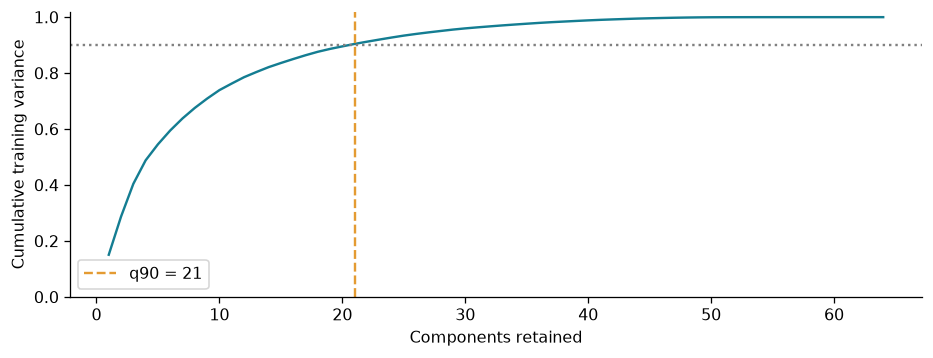

In [3]:
basis = PCA(n_components=64, svd_solver="full", whiten=False).fit(X_train)
cumulative = np.cumsum(basis.explained_variance_ratio_)
q90 = int(np.searchsorted(cumulative, 0.90) + 1)
threshold_pca = PCA(n_components=0.90, svd_solver="full").fit(X_train)
assert q90 == threshold_pca.n_components_
np.testing.assert_allclose(basis.mean_, X_train.mean(axis=0))
train_scores = basis.transform(X_train)
test_scores = basis.transform(X_test)
print(f"q90 = {q90} of 64; retained training variance = {cumulative[q90-1]:.2%}")
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.plot(np.arange(1, 65), cumulative, color=COLORS[0])
ax.axhline(0.90, ls=":", color="0.5")
ax.axvline(q90, ls="--", color=COLORS[1], label=f"q90 = {q90}")
ax.set(xlabel="Components retained", ylabel="Cumulative training variance", ylim=(0, 1.02))
ax.legend()
save_figure(fig, "digits_variance")
plt.show()

## 3. Measure reconstruction on training and held-out rows

Use the same fitted mean and directions for every q. Reconstruct by adding
retained score × direction contributions to the training mean.
MSE is averaged over all rows and all 64 original features. Values are not clipped
for metric computation. Adding directions cannot increase a row's orthogonal
reconstruction error, even for new rows projected onto this fixed nested basis.

,train_variance,train_MSE,test_MSE
q,,,
1,0.1509,15.8961,16.2706
2,0.2874,13.3412,13.6851
5,0.5456,8.5070,8.6909
10,0.7392,4.8827,5.0613
21,0.9043,1.7915,1.9465
32,0.9670,0.6169,0.7033
64,1.0000,0.0000,0.0000


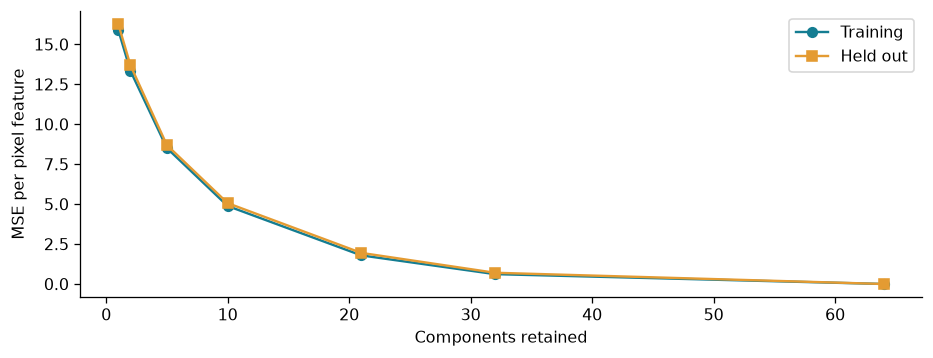

In [4]:
def reconstruct(scores, q):
    return scores[:, :q] @ basis.components_[:q] + basis.mean_

q_values = sorted(set([1, 2, 5, 10, q90, 32, 64]))
error_rows = []
for q in q_values:
    train_error = float(np.mean((X_train-reconstruct(train_scores, q))**2))
    test_error = float(np.mean((X_test-reconstruct(test_scores, q))**2))
    error_rows.append({"q": q, "train_variance": cumulative[q-1],
                       "train_MSE": train_error, "test_MSE": test_error})
errors = pd.DataFrame(error_rows).set_index("q")
display(errors.round(4))
assert np.all(np.diff(errors.train_MSE) <= 1e-10)
assert np.all(np.diff(errors.test_MSE) <= 1e-10)
np.testing.assert_allclose(reconstruct(test_scores, 64), X_test, atol=1e-12)
expected_sse = (len(X_train)-1)*basis.explained_variance_[q90:].sum()
np.testing.assert_allclose(np.sum((X_train-reconstruct(train_scores, q90))**2), expected_sse)
np.testing.assert_allclose(threshold_pca.inverse_transform(threshold_pca.transform(X_test)),
                           reconstruct(test_scores, q90), atol=1e-11)
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.plot(errors.index, errors.train_MSE, "o-", label="Training", color=COLORS[0])
ax.plot(errors.index, errors.test_MSE, "s-", label="Held out", color=COLORS[1])
ax.set(xlabel="Components retained", ylabel="MSE per pixel feature")
ax.legend()
save_figure(fig, "digits_error")
plt.show()

## 4. Inspect the same held-out images at different dimensions

Show the first eight test rows in split order, without selecting especially good
reconstructions. Every panel uses the same displayed range 0–16. Display saturation
does not change the unmodified values used for the MSE above.

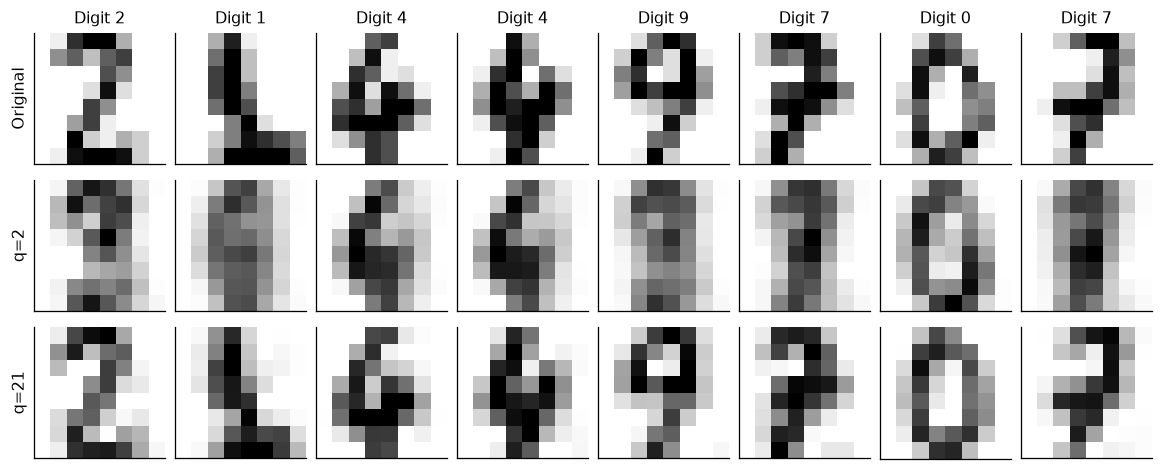

In [5]:
q2_images = reconstruct(test_scores, 2)
q90_images = reconstruct(test_scores, q90)
fig, axes = plt.subplots(3, 8, figsize=(10, 4), constrained_layout=True)
for row, (images, row_label) in enumerate([(X_test, "Original"),
             (q2_images, "q=2"), (q90_images, f"q={q90}")]):
    for column in range(8):
        axes[row, column].imshow(images[column].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        axes[row, column].set(xticks=[], yticks=[])
        if row == 0:
            axes[row, column].set_title(f"Digit {y_test[column]}", fontsize=10)
    axes[row, 0].set_ylabel(row_label, fontsize=10)
save_figure(fig, "digits_reconstructions")
plt.show()

## 5. View component patterns and a two-score projection

Each 64-entry direction can be reshaped into an 8×8 coefficient image. A score
scales that signed pattern before it is added to the mean image. Positive and
negative colors show signed coefficients; each component's overall sign is arbitrary.
Test labels only color the score plot; they were not used to fit its axes.

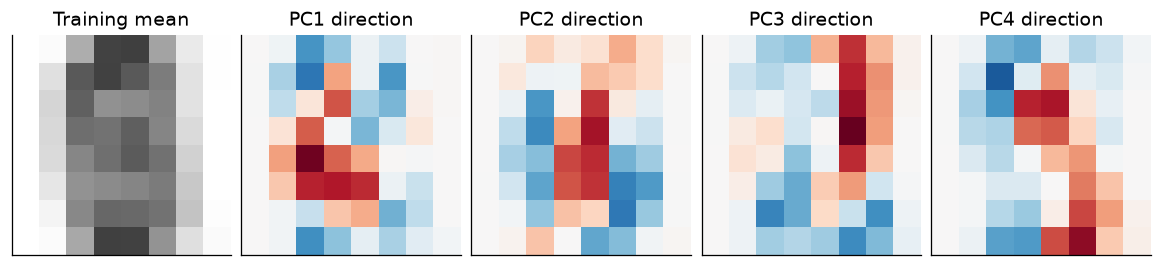

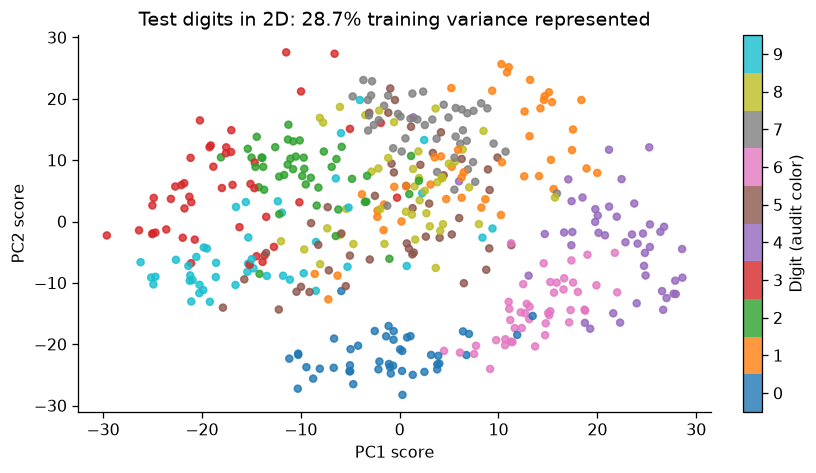

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2.2), constrained_layout=True)
axes[0].imshow(basis.mean_.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
axes[0].set_title("Training mean")
for j, ax in enumerate(axes[1:]):
    limit = np.abs(basis.components_[:4]).max()
    ax.imshow(basis.components_[j].reshape(8, 8), cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(f"PC{j+1} direction")
for ax in axes:
    ax.set(xticks=[], yticks=[])
save_figure(fig, "digits_components")
plt.show()
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
sc = ax.scatter(test_scores[:, 0], test_scores[:, 1], c=y_test,
                cmap="tab10", vmin=-0.5, vmax=9.5, s=19, alpha=0.8)
fig.colorbar(sc, ax=ax, ticks=range(10), label="Digit (audit color)")
ax.set(xlabel="PC1 score", ylabel="PC2 score",
       title=f"Test digits in 2D: {cumulative[1]:.1%} training variance represented")
save_figure(fig, "digits_projection")
plt.show()

## 6. A separate supervised task: predict the digit

PCA alone does not classify. Fit fixed logistic regression models to compare
all 64 centered pixel features with the q90 representation. `C=1` and
`max_iter=3000` are fixed; no test result selects features or settings.
Pipelines fit centering/PCA only on training rows. This is a single random
image split within the packaged subset, not a writer-independent evaluation.

A variance fraction and a classification accuracy answer different questions.
Compare both alongside reconstruction error rather than interpret 90% variance
as 90% predictive accuracy or a guaranteed speed improvement.

,features,test_accuracy
Centered pixels + logistic,64,0.9733
PCA + logistic,21,0.9511


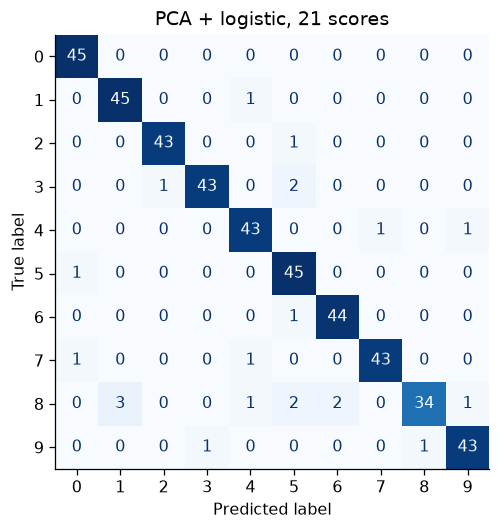

265

In [7]:
baseline = make_pipeline(StandardScaler(with_std=False),
                         LogisticRegression(C=1.0, max_iter=3000))
compressed = make_pipeline(PCA(n_components=0.90, svd_solver="full"),
                           LogisticRegression(C=1.0, max_iter=3000))
baseline.fit(X_train, y_train)
compressed.fit(X_train, y_train)
full_accuracy = accuracy_score(y_test, baseline.predict(X_test))
compressed_accuracy = accuracy_score(y_test, compressed.predict(X_test))
assert compressed.named_steps["pca"].n_components_ == q90
np.testing.assert_allclose(compressed.named_steps["pca"].mean_, X_train.mean(axis=0))
for pipeline in [baseline, compressed]:
    assert np.all(pipeline.named_steps["logisticregression"].n_iter_ < 3000)
display(pd.DataFrame({"features": [64, q90],
                      "test_accuracy": [full_accuracy, compressed_accuracy]},
                     index=["Centered pixels + logistic", "PCA + logistic"]).round(4))
fig, ax = plt.subplots(figsize=(5, 4.5), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_test, compressed.predict(X_test),
    ax=ax, colorbar=False, cmap="Blues", values_format="d")
ax.set_title(f"PCA + logistic, {q90} scores")
save_figure(fig, "digits_confusion")
plt.show()
summary = {"train_n": len(X_train), "test_n": len(X_test), "q90": q90,
           "retained": float(cumulative[q90-1]), "two_pc": float(cumulative[1]),
           "train_mse": float(errors.loc[q90, "train_MSE"]),
           "test_mse": float(errors.loc[q90, "test_MSE"]),
           "full_accuracy": float(full_accuracy), "pca_accuracy": float(compressed_accuracy)}
(ROOT / ".build" / "digits_metrics.json").write_text(json.dumps(summary, indent=2) + "\n")

## 7. Exercises with reference solutions

1. Find the smallest q retaining at least 95% of training variance. Report its
   training reconstruction MSE. Do not use test scores to choose q.
2. Calculate how many real-valued numbers the training representation stores:
   nq scores + qp directions + p mean entries. Compare that with np pixel entries.
   Explain why the ratio is not a file-size or byte-compression ratio.

In [8]:
# Reference solution 1
q95 = int(np.searchsorted(cumulative, 0.95) + 1)
print({"q95": q95, "training_variance": round(float(cumulative[q95-1]), 5),
       "training_MSE": round(float(np.mean((X_train-reconstruct(train_scores, q95))**2)), 5)})

# Reference solution 2
n, p = X_train.shape
original_entries = n * p
encoded_entries = n*q90 + q90*p + p
print({"original_entries": original_entries, "PCA_entries_including_basis_and_mean": encoded_entries,
       "entry_ratio": round(encoded_entries/original_entries, 4)})
# Pixel counts can be small integers, while PCA scores/basis use floating point;
# real compression also depends on quantization, metadata, and file encoding.

{'q95': 28, 'training_variance': 0.95058, 'training_MSE': 0.92518}
{'original_entries': 86208, 'PCA_entries_including_basis_and_mean': 29695, 'entry_ratio': 0.3445}


## Dataset credit

Alpaydin, E. & Kaynak, C. (1998). **Optical Recognition of Handwritten Digits** [Dataset].
UCI Machine Learning Repository. [DOI: 10.24432/C50P49](https://doi.org/10.24432/C50P49).
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
We use scikit-learn's bundled 1,797-image subset (the source dataset's test portion),
not the complete 5,620-image collection. Our train/test split subdivides this subset.
PCA projections, reconstructions, and coefficient patterns are analysis transformations.
See [load_digits documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

## Sources and attribution

Companion reading: GeeksforGeeks, [Principal Component Analysis (PCA)](https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-pca/)
(accessed 27 October 2026). The PDF includes a short attributed paraphrase and two credited
figures from that article. This notebook's code, experiments, and plots are original to this supplement.

Technical references: scikit-learn [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html),
[decomposition guide](https://scikit-learn.org/stable/modules/decomposition.html#pca), and
[preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
Full credits: [ATTRIBUTION.md](ATTRIBUTION.md).